In [2]:

from google.colab import files

uploaded = files.upload()

Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:


from IPython.display import display

orders = pd.read_csv('olist_orders_dataset.csv')

display(orders.head())



,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:


# Dataset Size
overview = pd.DataFrame({
    "Metric": ["Total Rows", "Total Columns"],
    "Value": [orders.shape[0], orders.shape[1]]
})

print("DATASET OVERVIEW")
display(overview)

# Column Information
column_info = pd.DataFrame({
    "Column Name": orders.columns,
    "Non-Null Count": orders.notnull().sum().values,
    "Missing Values": orders.isnull().sum().values,
    "Data Type": orders.dtypes.astype(str).values
})

print("COLUMN INFORMATION")
display(column_info)



DATASET OVERVIEW


,Metric,Value
0,Total Rows,99441
1,Total Columns,8


COLUMN INFORMATION


,Column Name,Non-Null Count,Missing Values,Data Type
0,order_id,99441,0,object
1,customer_id,99441,0,object
2,order_status,99441,0,object
3,order_purchase_timestamp,99441,0,object
4,order_approved_at,99281,160,object
5,order_delivered_carrier_date,97658,1783,object
6,order_delivered_customer_date,96476,2965,object
7,order_estimated_delivery_date,99441,0,object


In [8]:

# Order Status Analysis

order_status = orders['order_status'].value_counts().reset_index()

order_status.columns = ['Order Status', 'Number of Orders']

print("ORDER STATUS ANALYSIS")
display(order_status)


ORDER STATUS ANALYSIS


,Order Status,Number of Orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [9]:

# Missing Value Analysis

missing_data = pd.DataFrame({
    'Column Name': orders.columns,
    'Missing Values': orders.isnull().sum().values,
    'Missing Percentage': (
        orders.isnull().sum().values / len(orders) * 100
    ).round(2)
})

print("MISSING VALUE ANALYSIS")
display(missing_data)


MISSING VALUE ANALYSIS


,Column Name,Missing Values,Missing Percentage
0,order_id,0,0.00
1,customer_id,0,0.00
2,order_status,0,0.00
3,order_purchase_timestamp,0,0.00
4,order_approved_at,160,0.16
5,order_delivered_carrier_date,1783,1.79
6,order_delivered_customer_date,2965,2.98
7,order_estimated_delivery_date,0,0.00


In [10]:

# Duplicate Analysis

duplicate_count = orders.duplicated(subset=['order_id']).sum()

print("DUPLICATE ORDER ANALYSIS")

display(pd.DataFrame({
    'Metric': ['Total Orders', 'Duplicate Order IDs'],
    'Count': [len(orders), duplicate_count]
}))


DUPLICATE ORDER ANALYSIS


,Metric,Count
0,Total Orders,99441
1,Duplicate Order IDs,0


In [11]:

# Create a copy of the original dataset

orders_clean = orders.copy()

# Identify date columns

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

# Convert columns into datetime format

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors='coerce'
    )

print("DATE CONVERSION COMPLETED")

# Display updated data types

date_info = pd.DataFrame({
    'Column Name': orders_clean[date_columns].columns,
    'Data Type': orders_clean[date_columns].dtypes.astype(str).values
})

display(date_info)


DATE CONVERSION COMPLETED


,Column Name,Data Type
0,order_purchase_timestamp,datetime64[ns]
1,order_approved_at,datetime64[ns]
2,order_delivered_carrier_date,datetime64[ns]
3,order_delivered_customer_date,datetime64[ns]
4,order_estimated_delivery_date,datetime64[ns]


In [12]:

# Missing Values by Order Status

missing_by_status = orders_clean.groupby('order_status').agg(
    Total_Orders=('order_id', 'count'),
    Missing_Approval=('order_approved_at',
                      lambda x: x.isnull().sum()),
    Missing_Carrier_Date=('order_delivered_carrier_date',
                          lambda x: x.isnull().sum()),
    Missing_Delivery_Date=('order_delivered_customer_date',
                           lambda x: x.isnull().sum())
).reset_index()

print("MISSING VALUES BY ORDER STATUS")
display(missing_by_status)


MISSING VALUES BY ORDER STATUS


,order_status,Total_Orders,Missing_Approval,Missing_Carrier_Date,Missing_Delivery_Date
0,approved,2,0,2,2
1,canceled,625,141,550,619
2,created,5,5,5,5
3,delivered,96478,14,2,8
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,shipped,1107,0,0,1107
7,unavailable,609,0,609,609


In [13]:

# Calculate Delivery Time

orders_clean['delivery_time_days'] = (
    orders_clean['order_delivered_customer_date'] -
    orders_clean['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Select only delivered orders

delivered_orders = orders_clean[
    orders_clean['order_status'] == 'delivered'
].copy()

# Calculate delivery statistics

delivery_summary = pd.DataFrame({
    'Metric': [
        'Total Delivered Orders',
        'Average Delivery Time (Days)',
        'Minimum Delivery Time (Days)',
        'Maximum Delivery Time (Days)'
    ],
    'Value': [
        len(delivered_orders),
        round(delivered_orders['delivery_time_days'].mean(), 2),
        round(delivered_orders['delivery_time_days'].min(), 2),
        round(delivered_orders['delivery_time_days'].max(), 2)
    ]
})

print("DELIVERY TIME ANALYSIS")
display(delivery_summary)


DELIVERY TIME ANALYSIS


,Metric,Value
0,Total Delivered Orders,96478.00
1,Average Delivery Time (Days),12.56
2,Minimum Delivery Time (Days),0.53
3,Maximum Delivery Time (Days),209.63


In [14]:

# Delayed Delivery Analysis

delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

delivered_orders['delivery_performance'] = np.where(
    delivered_orders['delivery_delay_days'] > 0,
    'Delayed',
    'On Time or Early'
)

delay_summary = (
    delivered_orders['delivery_performance']
    .value_counts()
    .reset_index()
)

delay_summary.columns = [
    'Delivery Performance',
    'Number of Orders'
]

print("DELIVERY PERFORMANCE ANALYSIS")
display(delay_summary)


DELIVERY PERFORMANCE ANALYSIS


,Delivery Performance,Number of Orders
0,On Time or Early,88652
1,Delayed,7826


In [15]:

# Corrected Delivery Performance Analysis

delivery_analysis = delivered_orders.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
).copy()

delivery_analysis['delivery_delay_days'] = (
    delivery_analysis['order_delivered_customer_date'] -
    delivery_analysis['order_estimated_delivery_date']
).dt.total_seconds() / 86400

delivery_analysis['delivery_performance'] = np.where(
    delivery_analysis['delivery_delay_days'] > 0,
    'Delayed',
    'On Time or Early'
)

performance = (
    delivery_analysis['delivery_performance']
    .value_counts()
    .reset_index()
)

performance.columns = ['Delivery Performance', 'Number of Orders']

performance['Percentage'] = (
    performance['Number of Orders'] /
    len(delivery_analysis) * 100
).round(2)

print("CORRECTED DELIVERY PERFORMANCE")
display(performance)


CORRECTED DELIVERY PERFORMANCE


,Delivery Performance,Number of Orders,Percentage
0,On Time or Early,88644,91.89
1,Delayed,7826,8.11


In [16]:

# Step 14: Monthly Order Trend Analysis

orders_clean['purchase_month'] = (
    orders_clean['order_purchase_timestamp']
    .dt.to_period('M')
)

monthly_orders = (
    orders_clean.groupby('purchase_month')
    .size()
    .reset_index(name='Total Orders')
)

monthly_orders['purchase_month'] = (
    monthly_orders['purchase_month'].astype(str)
)

print("MONTHLY ORDER ANALYSIS")
display(monthly_orders)


MONTHLY ORDER ANALYSIS


,purchase_month,Total Orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


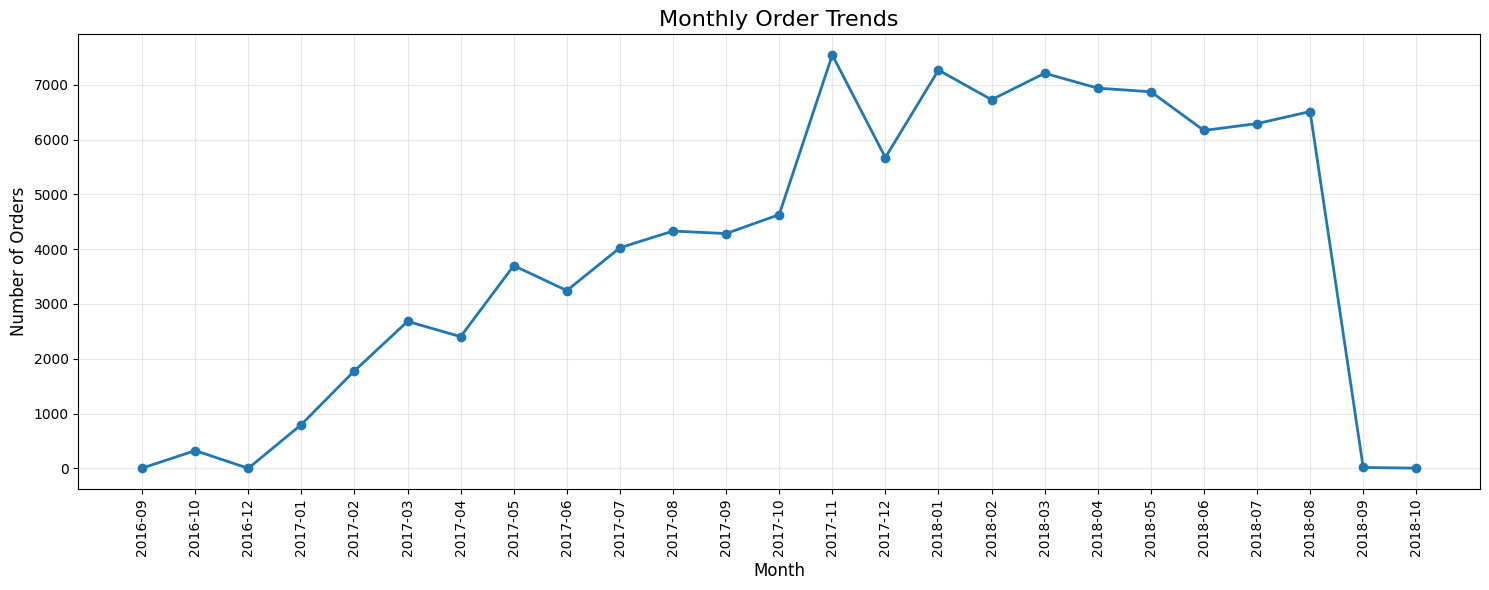

In [17]:

# Step 15: Monthly Order Trend Visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_orders['purchase_month'],
    monthly_orders['Total Orders'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Order Trends', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)

plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [18]:

# Check all loaded datasets

dataframes = [
    name for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
]

print("AVAILABLE DATASETS:")
for name in dataframes:
    print(name)


AVAILABLE DATASETS:
orders
overview
column_info
order_status
missing_data
orders_clean
date_info
missing_by_status
delivered_orders
delivery_summary
delay_summary
delivery_analysis
performance
monthly_orders


In [19]:

import os

# Check available CSV files
csv_files = [f for f in os.listdir() if f.endswith('.csv')]

print("AVAILABLE CSV FILES:")
for file in csv_files:
    print(file)


AVAILABLE CSV FILES:
olist_order_payments_dataset.csv
olist_products_dataset.csv
olist_geolocation_dataset.csv
olist_order_reviews_dataset.csv
olist_order_items_dataset.csv
olist_sellers_dataset.csv
olist_customers_dataset.csv
olist_orders_dataset.csv
product_category_name_translation.csv


In [20]:

# Step 16.2: Load Payments Dataset

payments = pd.read_csv('olist_order_payments_dataset.csv')

print("PAYMENTS DATASET")
display(payments.head())


PAYMENTS DATASET


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [21]:

# Step 16.3: Payments Dataset Overview

payment_info = pd.DataFrame({
    'Column Name': payments.columns,
    'Non-Null Values': payments.notnull().sum().values,
    'Missing Values': payments.isnull().sum().values,
    'Data Type': payments.dtypes.astype(str).values
})

print("PAYMENTS DATASET INFORMATION")

display(payment_info)


PAYMENTS DATASET INFORMATION


,Column Name,Non-Null Values,Missing Values,Data Type
0,order_id,103886,0,object
1,payment_sequential,103886,0,int64
2,payment_type,103886,0,object
3,payment_installments,103886,0,int64
4,payment_value,103886,0,float64


In [22]:

# Step 17: Total Revenue Analysis

total_revenue = payments['payment_value'].sum()

total_orders_paid = payments['order_id'].nunique()

average_order_value = total_revenue / total_orders_paid

revenue_summary = pd.DataFrame({
    'Metric': [
        'Total Revenue',
        'Total Unique Orders Paid',
        'Average Order Value'
    ],
    'Value': [
        round(total_revenue, 2),
        total_orders_paid,
        round(average_order_value, 2)
    ]
})

print("REVENUE SUMMARY")
display(revenue_summary)


REVENUE SUMMARY


,Metric,Value
0,Total Revenue,16008872.12
1,Total Unique Orders Paid,99440.00
2,Average Order Value,160.99


In [23]:

# Step 18: Payment Method Analysis

payment_methods = (
    payments.groupby('payment_type')
    .agg(
        Total_Transactions=('payment_type', 'count'),
        Total_Revenue=('payment_value', 'sum')
    )
    .reset_index()
)

payment_methods['Revenue_Percentage'] = (
    payment_methods['Total_Revenue'] /
    payment_methods['Total_Revenue'].sum() * 100
).round(2)

payment_methods = payment_methods.sort_values(
    by='Total_Revenue',
    ascending=False
)

print("PAYMENT METHOD ANALYSIS")
display(payment_methods)


PAYMENT METHOD ANALYSIS


,payment_type,Total_Transactions,Total_Revenue,Revenue_Percentage
1,credit_card,76795,12542084.19,78.34
0,boleto,19784,2869361.27,17.92
4,voucher,5775,379436.87,2.37
2,debit_card,1529,217989.79,1.36
3,not_defined,3,0.00,0.00


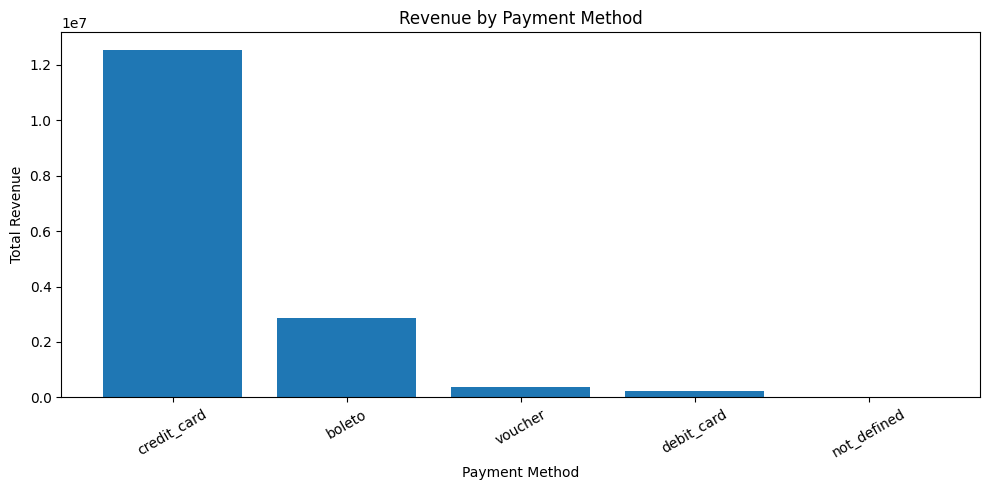

In [24]:

# Step 19: Payment Method Visualization

plt.figure(figsize=(10, 5))

plt.bar(
    payment_methods['payment_type'],
    payment_methods['Total_Revenue']
)

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Revenue')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [25]:
# INSTALLMENT ANALYSIS

installment_analysis = payments.groupby('payment_installments').agg(
    Total_Transactions=('order_id', 'count'),
    Total_Revenue=('payment_value', 'sum'),
    Average_Payment=('payment_value', 'mean')
).reset_index()

installment_analysis = installment_analysis.round(2)

print("INSTALLMENT ANALYSIS")
display(installment_analysis)

INSTALLMENT ANALYSIS


,payment_installments,Total_Transactions,Total_Revenue,Average_Payment
0,0,2,188.63,94.32
1,1,52546,5907233.36,112.42
2,2,12413,1579283.03,127.23
3,3,10461,1491103.80,142.54
4,4,7098,1163907.61,163.98
5,5,5239,961174.30,183.47
6,6,3920,822611.81,209.85
7,7,1626,305157.39,187.67
8,8,4268,1313423.34,307.74
9,9,644,131015.92,203.44


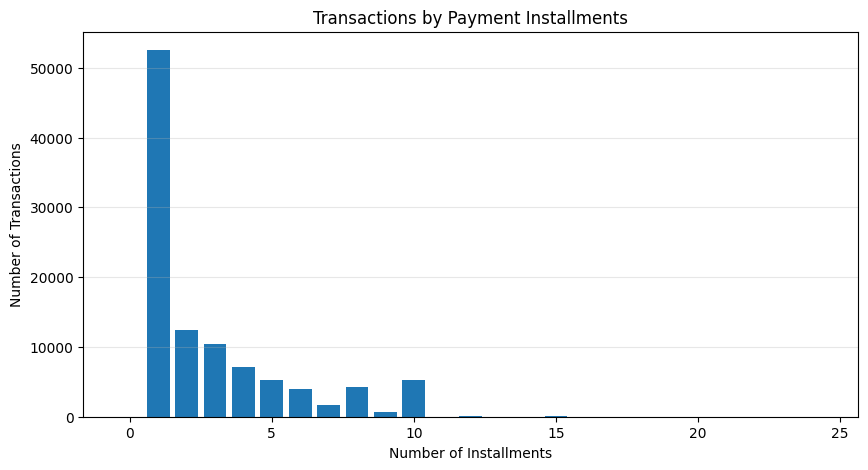

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(
    installment_analysis['payment_installments'],
    installment_analysis['Total_Transactions']
)

plt.title('Transactions by Payment Installments')
plt.xlabel('Number of Installments')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [27]:
# PRODUCTS DATASET

products = pd.read_csv('olist_products_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')

print("PRODUCT DATASET")
display(products.head())

print("PRODUCT DATASET SIZE")
display(pd.DataFrame({
    'Metric': ['Total Rows', 'Total Columns'],
    'Value': [products.shape[0], products.shape[1]]
}))

# Missing value analysis
product_missing = pd.DataFrame({
    'Column Name': products.columns,
    'Missing Values': products.isnull().sum().values,
    'Missing Percentage': (
        products.isnull().sum().values / len(products) * 100
    ).round(2)
})

print("PRODUCT MISSING VALUE ANALYSIS")
display(product_missing)

PRODUCT DATASET


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


PRODUCT DATASET SIZE


,Metric,Value
0,Total Rows,32951
1,Total Columns,9


PRODUCT MISSING VALUE ANALYSIS


,Column Name,Missing Values,Missing Percentage
0,product_id,0,0.00
1,product_category_name,610,1.85
2,product_name_lenght,610,1.85
3,product_description_lenght,610,1.85
4,product_photos_qty,610,1.85
5,product_weight_g,2,0.01
6,product_length_cm,2,0.01
7,product_height_cm,2,0.01
8,product_width_cm,2,0.01


In [28]:
# PRODUCT CATEGORY ANALYSIS

category_sales = order_items.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

top_categories = category_sales.groupby(
    'product_category_name'
).agg(
    Total_Items=('product_id', 'count'),
    Total_Revenue=('price', 'sum')
).reset_index()

top_categories = top_categories.sort_values(
    by='Total_Revenue', ascending=False
).head(10)

top_categories['Total_Revenue'] = top_categories['Total_Revenue'].round(2)

print("TOP 10 PRODUCT CATEGORIES")
display(top_categories)

TOP 10 PRODUCT CATEGORIES


,product_category_name,Total_Items,Total_Revenue
11,beleza_saude,9670,1258681.34
66,relogios_presentes,5991,1205005.68
13,cama_mesa_banho,11115,1036988.68
32,esporte_lazer,8641,988048.97
44,informatica_acessorios,7827,911954.32
54,moveis_decoracao,8334,729762.49
26,cool_stuff,3796,635290.85
72,utilidades_domesticas,6964,632248.66
8,automotivo,4235,592720.11
40,ferramentas_jardim,4347,485256.46


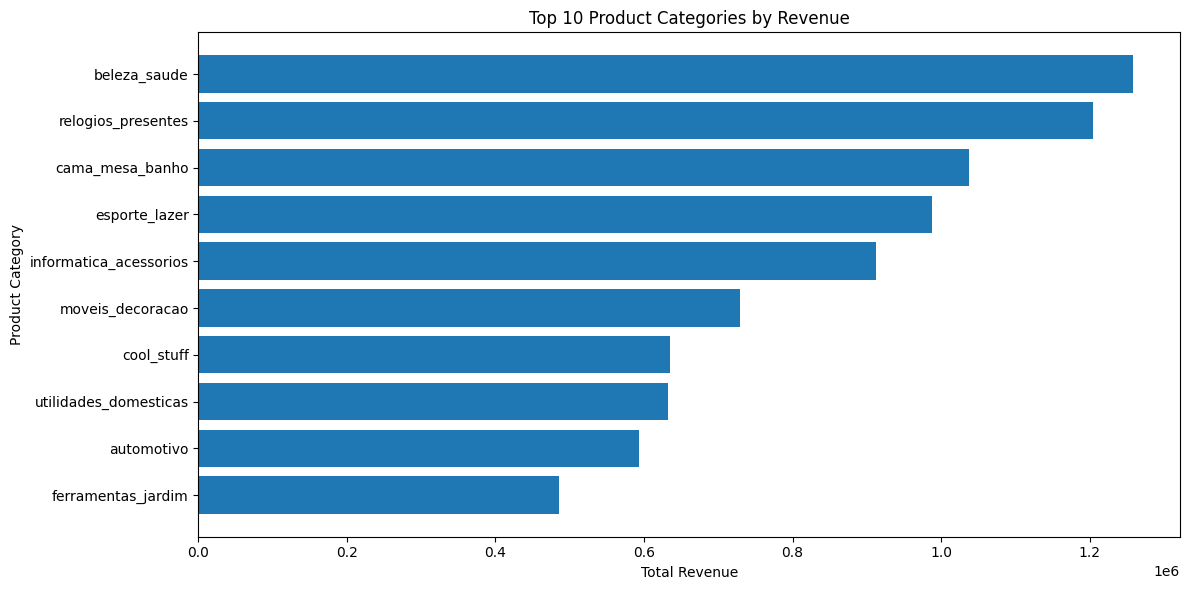

In [29]:
plt.figure(figsize=(12,6))

plt.barh(
    top_categories['product_category_name'],
    top_categories['Total_Revenue']
)

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Category')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [30]:

# CUSTOMER DATASET ANALYSIS

customers = pd.read_csv('olist_customers_dataset.csv')

print("CUSTOMER DATASET")
display(customers.head())

print("\nCUSTOMER DATASET SIZE")
print("Total Rows:", customers.shape[0])
print("Total Columns:", customers.shape[1])

print("\nCUSTOMER DATASET INFORMATION")
display(pd.DataFrame({
    'Column Name': customers.columns,
    'Non-Null Values': customers.notnull().sum().values,
    'Missing Values': customers.isnull().sum().values,
    'Data Type': customers.dtypes.values
}))


CUSTOMER DATASET


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



CUSTOMER DATASET SIZE
Total Rows: 99441
Total Columns: 5

CUSTOMER DATASET INFORMATION


,Column Name,Non-Null Values,Missing Values,Data Type
0,customer_id,99441,0,object
1,customer_unique_id,99441,0,object
2,customer_zip_code_prefix,99441,0,int64
3,customer_city,99441,0,object
4,customer_state,99441,0,object


In [31]:

duplicate_customers = customers.duplicated(
    subset=['customer_id']
).sum()

print("CUSTOMER DUPLICATE ANALYSIS")

display(pd.DataFrame({
    'Metric': ['Total Customers', 'Duplicate Customer IDs'],
    'Count': [len(customers), duplicate_customers]
}))


CUSTOMER DUPLICATE ANALYSIS


,Metric,Count
0,Total Customers,99441
1,Duplicate Customer IDs,0


In [32]:

customer_state = customers['customer_state'].value_counts().reset_index()

customer_state.columns = ['State', 'Number of Customers']

print("CUSTOMER DISTRIBUTION BY STATE")
display(customer_state)


CUSTOMER DISTRIBUTION BY STATE


,State,Number of Customers
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


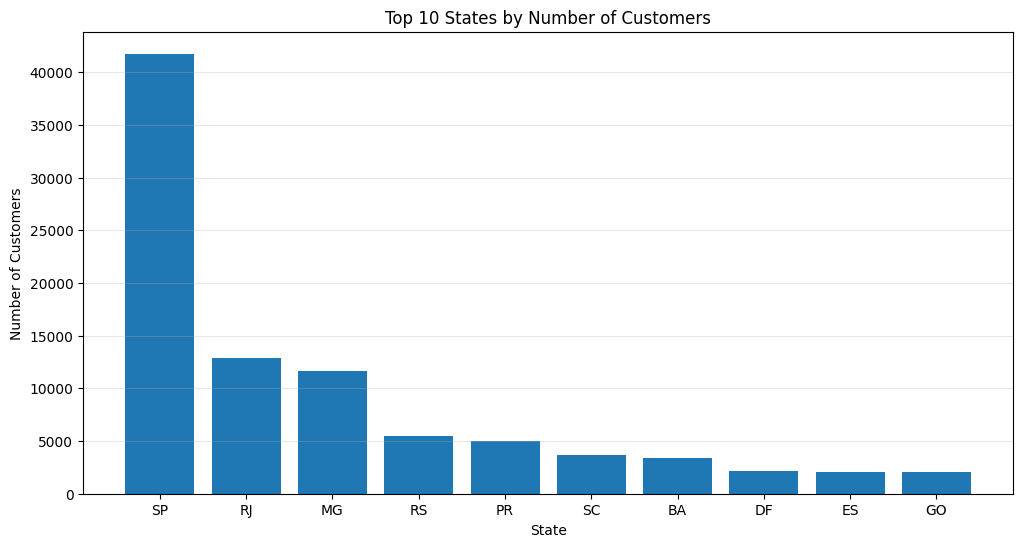

In [33]:

import matplotlib.pyplot as plt

top_states = customer_state.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top_states['State'], top_states['Number of Customers'])

plt.title('Top 10 States by Number of Customers')
plt.xlabel('State')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)
plt.show()


In [34]:

# GEOLOCATION DATASET ANALYSIS

geolocation = pd.read_csv('olist_geolocation_dataset.csv')

print("GEOLOCATION DATASET")
display(geolocation.head())

print("\nGEOLOCATION DATASET SIZE")
print("Total Rows:", geolocation.shape[0])
print("Total Columns:", geolocation.shape[1])

print("\nGEOLOCATION DATASET INFORMATION")
display(pd.DataFrame({
    'Column Name': geolocation.columns,
    'Non-Null Values': geolocation.notnull().sum().values,
    'Missing Values': geolocation.isnull().sum().values,
    'Data Type': geolocation.dtypes.values
}))


GEOLOCATION DATASET


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



GEOLOCATION DATASET SIZE
Total Rows: 1000163
Total Columns: 5

GEOLOCATION DATASET INFORMATION


,Column Name,Non-Null Values,Missing Values,Data Type
0,geolocation_zip_code_prefix,1000163,0,int64
1,geolocation_lat,1000163,0,float64
2,geolocation_lng,1000163,0,float64
3,geolocation_city,1000163,0,object
4,geolocation_state,1000163,0,object


In [35]:

duplicate_geo = geolocation.duplicated().sum()

print("GEOLOCATION DUPLICATE ANALYSIS")

display(pd.DataFrame({
    'Metric': ['Total Records', 'Duplicate Records'],
    'Count': [len(geolocation), duplicate_geo]
}))


GEOLOCATION DUPLICATE ANALYSIS


,Metric,Count
0,Total Records,1000163
1,Duplicate Records,261831


In [36]:

geo_state = geolocation.groupby(
    'geolocation_state'
).size().reset_index(name='Total Records')

geo_state = geo_state.sort_values(
    by='Total Records', ascending=False
)

print("GEOLOCATION DISTRIBUTION BY STATE")
display(geo_state.head(10))


GEOLOCATION DISTRIBUTION BY STATE


,geolocation_state,Total Records
25,SP,404268
10,MG,126336
18,RJ,121169
22,RS,61851
17,PR,57859
23,SC,38328
4,BA,36045
8,GO,20139
7,ES,16748
15,PE,16432


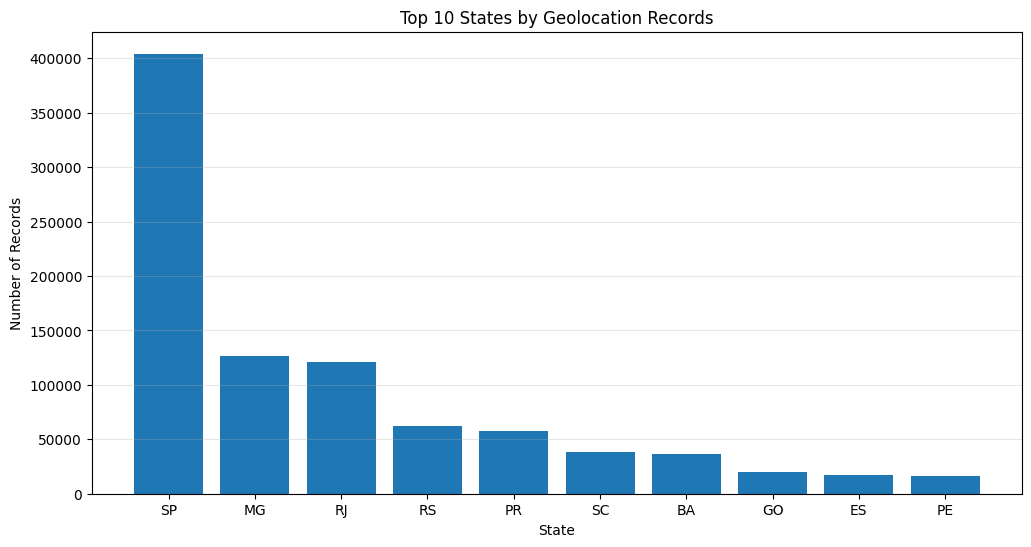

In [37]:

top_geo = geo_state.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top_geo['geolocation_state'], top_geo['Total Records'])

plt.title('Top 10 States by Geolocation Records')
plt.xlabel('State')
plt.ylabel('Number of Records')
plt.grid(axis='y', alpha=0.3)
plt.show()


In [40]:

print("AVAILABLE DATAFRAMES:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)


AVAILABLE DATAFRAMES:
orders (99441, 8)
overview (2, 2)
column_info (8, 4)
order_status (8, 2)
missing_data (8, 3)
orders_clean (99441, 10)
date_info (5, 2)
missing_by_status (8, 5)
delivered_orders (96478, 11)
delivery_summary (4, 2)
delay_summary (2, 2)
delivery_analysis (96470, 11)
performance (2, 3)
monthly_orders (25, 2)
payments (103886, 5)
payment_info (5, 4)
revenue_summary (3, 2)
payment_methods (5, 4)
installment_analysis (24, 4)
products (32951, 9)
order_items (112650, 7)
product_missing (9, 3)
category_sales (112650, 8)
top_categories (10, 3)
customers (99441, 5)
customer_state (27, 2)
top_states (10, 2)
geolocation (1000163, 5)
geo_state (27, 2)
top_geo (10, 2)


In [41]:

# LOAD SELLER DATASET

sellers = pd.read_csv('olist_sellers_dataset.csv')

print("SELLER DATASET LOADED SUCCESSFULLY")
display(sellers.head())

print("Dataset Shape:", sellers.shape)


SELLER DATASET LOADED SUCCESSFULLY


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


Dataset Shape: (3095, 4)


SELLER DATASET SIZE
Total Rows: 3095
Total Columns: 4

SELLER DATASET INFORMATION


,Column Name,Non-Null Values,Missing Values,Data Type
0,seller_id,3095,0,object
1,seller_zip_code_prefix,3095,0,int64
2,seller_city,3095,0,object
3,seller_state,3095,0,object



SELLER DUPLICATE ANALYSIS


,Metric,Count
0,Total Sellers,3095
1,Duplicate Seller IDs,0



SELLER DISTRIBUTION BY STATE


,seller_state,count
0,SP,1849
1,PR,349
2,MG,244
3,SC,190
4,RJ,171
5,RS,129
6,GO,40
7,DF,30
8,ES,23
9,BA,19


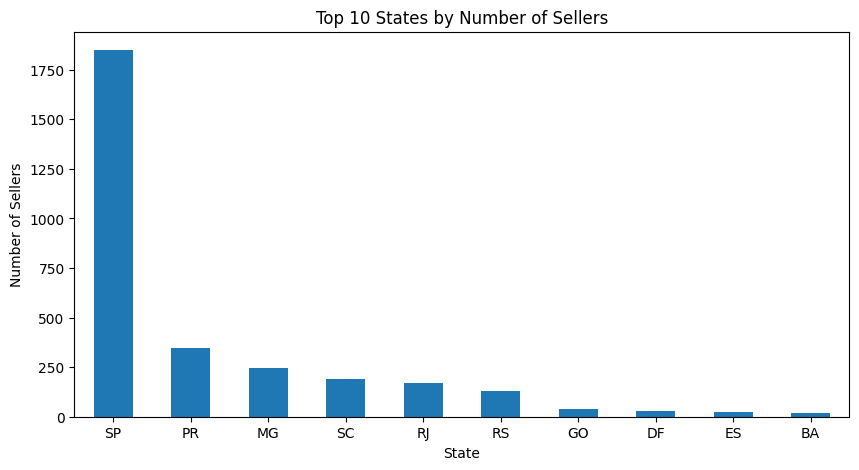

In [42]:

# =====================================
# SELLER DATASET ANALYSIS
# =====================================

print("SELLER DATASET SIZE")
print("Total Rows:", sellers.shape[0])
print("Total Columns:", sellers.shape[1])

print("\nSELLER DATASET INFORMATION")

seller_info = pd.DataFrame({
    'Column Name': sellers.columns,
    'Non-Null Values': sellers.notnull().sum().values,
    'Missing Values': sellers.isnull().sum().values,
    'Data Type': sellers.dtypes.values
})

display(seller_info)

print("\nSELLER DUPLICATE ANALYSIS")

display(pd.DataFrame({
    'Metric': ['Total Sellers', 'Duplicate Seller IDs'],
    'Count': [
        len(sellers),
        sellers['seller_id'].duplicated().sum()
    ]
}))

print("\nSELLER DISTRIBUTION BY STATE")

seller_state = sellers['seller_state'].value_counts().head(10)

display(seller_state.reset_index())

plt.figure(figsize=(10,5))
seller_state.plot(kind='bar')
plt.title("Top 10 States by Number of Sellers")
plt.xlabel("State")
plt.ylabel("Number of Sellers")
plt.xticks(rotation=0)
plt.show()


ORDER ITEMS DATASET


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



ORDER ITEMS DATASET SIZE
Total Rows: 112650
Total Columns: 7

ORDER ITEMS DATASET INFORMATION


,Column Name,Non-Null Values,Missing Values,Data Type
0,order_id,112650,0,object
1,order_item_id,112650,0,int64
2,product_id,112650,0,object
3,seller_id,112650,0,object
4,shipping_limit_date,112650,0,object
5,price,112650,0,float64
6,freight_value,112650,0,float64



ORDER ITEMS SUMMARY


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000



TOP 10 SELLERS BY REVENUE


,seller_id,price
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
1,53243585a1d6dc2643021fd1853d8905,222776.05
2,4a3ca9315b744ce9f8e9374361493884,200472.92
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03
4,7c67e1448b00f6e969d365cea6b010ab,187923.89
5,7e93a43ef30c4f03f38b393420bc753a,176431.87
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55
9,955fee9216a65b617aa5c0531780ce60,135171.70


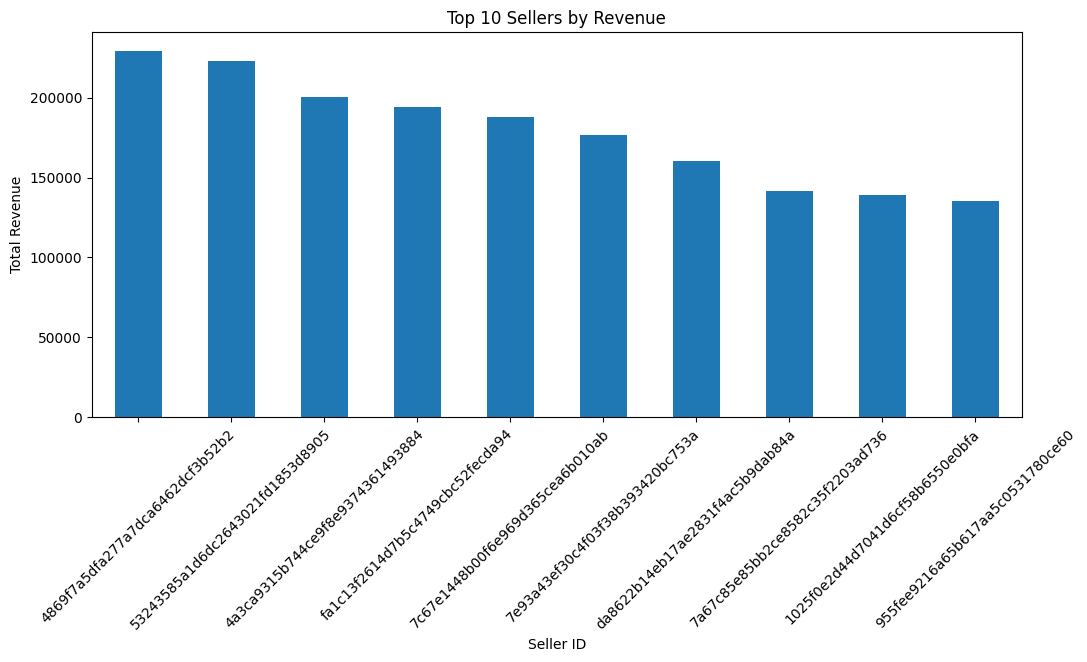


TOP 10 PRODUCTS BY SALES QUANTITY


,product_id,count
0,aca2eb7d00ea1a7b8ebd4e68314663af,527
1,99a4788cb24856965c36a24e339b6058,488
2,422879e10f46682990de24d770e7f83d,484
3,389d119b48cf3043d311335e499d9c6b,392
4,368c6c730842d78016ad823897a372db,388
5,53759a2ecddad2bb87a079a1f1519f73,373
6,d1c427060a0f73f6b889a5c7c61f2ac4,343
7,53b36df67ebb7c41585e8d54d6772e08,323
8,154e7e31ebfa092203795c972e5804a6,281
9,3dd2a17168ec895c781a9191c1e95ad7,274


In [43]:

# =====================================
# ORDER ITEMS DATASET ANALYSIS
# =====================================

print("ORDER ITEMS DATASET")

display(order_items.head())

print("\nORDER ITEMS DATASET SIZE")
print("Total Rows:", order_items.shape[0])
print("Total Columns:", order_items.shape[1])

print("\nORDER ITEMS DATASET INFORMATION")

order_items_info = pd.DataFrame({
    'Column Name': order_items.columns,
    'Non-Null Values': order_items.notnull().sum().values,
    'Missing Values': order_items.isnull().sum().values,
    'Data Type': order_items.dtypes.values
})

display(order_items_info)

print("\nORDER ITEMS SUMMARY")

display(order_items[['price', 'freight_value']].describe())

print("\nTOP 10 SELLERS BY REVENUE")

seller_revenue = order_items.groupby('seller_id')['price'].sum().sort_values(ascending=False).head(10)

display(seller_revenue.reset_index())

plt.figure(figsize=(12,5))
seller_revenue.plot(kind='bar')
plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

print("\nTOP 10 PRODUCTS BY SALES QUANTITY")

product_sales = order_items['product_id'].value_counts().head(10)

display(product_sales.reset_index())


In [44]:

# LOAD ORDER REVIEWS DATASET

reviews = pd.read_csv('olist_order_reviews_dataset.csv')

print("REVIEW DATASET LOADED")
display(reviews.head())

print("Dataset Shape:", reviews.shape)


REVIEW DATASET LOADED


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


Dataset Shape: (99224, 7)


REVIEW DATASET SIZE
Total Rows: 99224
Total Columns: 7

REVIEW DATASET INFORMATION


,Column Name,Non-Null Values,Missing Values,Data Type
0,review_id,99224,0,object
1,order_id,99224,0,object
2,review_score,99224,0,int64
3,review_comment_title,11568,87656,object
4,review_comment_message,40977,58247,object
5,review_creation_date,99224,0,object
6,review_answer_timestamp,99224,0,object



REVIEW SCORE DISTRIBUTION


,review_score,count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


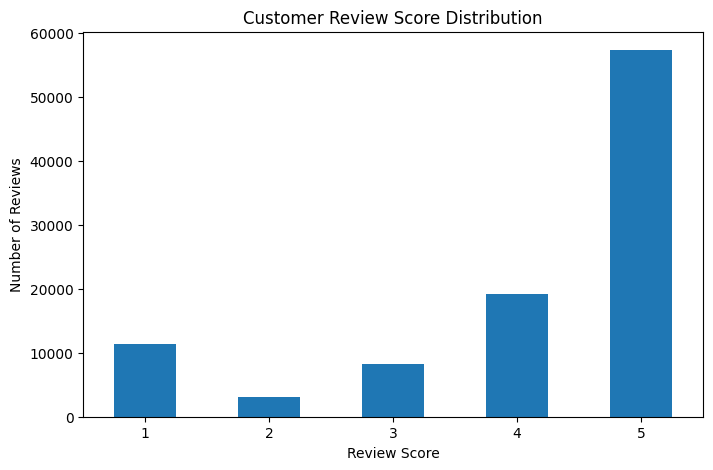


AVERAGE CUSTOMER REVIEW SCORE
4.08642062404257

REVIEW DUPLICATE ANALYSIS
Duplicate Review IDs: 814


In [45]:

# =====================================
# ORDER REVIEWS ANALYSIS
# =====================================

print("REVIEW DATASET SIZE")
print("Total Rows:", reviews.shape[0])
print("Total Columns:", reviews.shape[1])

print("\nREVIEW DATASET INFORMATION")

review_info = pd.DataFrame({
    'Column Name': reviews.columns,
    'Non-Null Values': reviews.notnull().sum().values,
    'Missing Values': reviews.isnull().sum().values,
    'Data Type': reviews.dtypes.values
})

display(review_info)

print("\nREVIEW SCORE DISTRIBUTION")

review_scores = reviews['review_score'].value_counts().sort_index()

display(review_scores.reset_index())

plt.figure(figsize=(8,5))
review_scores.plot(kind='bar')
plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

print("\nAVERAGE CUSTOMER REVIEW SCORE")
print(reviews['review_score'].mean())

print("\nREVIEW DUPLICATE ANALYSIS")
print("Duplicate Review IDs:", reviews['review_id'].duplicated().sum())


In [46]:
# ==========================================
# ORDER ITEMS DATASET ANALYSIS
# ==========================================

print("ORDER ITEMS DATASET")
print("=" * 50)

display(order_items.head())

print("\nORDER ITEMS DATASET SIZE")
print("Total Rows:", order_items.shape[0])
print("Total Columns:", order_items.shape[1])

print("\nORDER ITEMS DATASET INFORMATION")

order_item_info = pd.DataFrame({
    'Column Name': order_items.columns,
    'Non-Null Values': order_items.notnull().sum().values,
    'Missing Values': order_items.isnull().sum().values,
    'Data Type': order_items.dtypes.values
})

display(order_item_info)

ORDER ITEMS DATASET


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



ORDER ITEMS DATASET SIZE
Total Rows: 112650
Total Columns: 7

ORDER ITEMS DATASET INFORMATION


,Column Name,Non-Null Values,Missing Values,Data Type
0,order_id,112650,0,object
1,order_item_id,112650,0,int64
2,product_id,112650,0,object
3,seller_id,112650,0,object
4,shipping_limit_date,112650,0,object
5,price,112650,0,float64
6,freight_value,112650,0,float64


In [47]:
print("ORDER ITEMS DUPLICATE ANALYSIS")

duplicate_items = order_items.duplicated().sum()

duplicate_summary = pd.DataFrame({
    'Metric': ['Total Order Items', 'Duplicate Records'],
    'Count': [len(order_items), duplicate_items]
})

display(duplicate_summary)

ORDER ITEMS DUPLICATE ANALYSIS


,Metric,Count
0,Total Order Items,112650
1,Duplicate Records,0


In [48]:
print("ORDER ITEMS MISSING VALUE ANALYSIS")

missing_items = pd.DataFrame({
    'Column Name': order_items.columns,
    'Missing Values': order_items.isnull().sum().values,
    'Missing Percentage': (
        order_items.isnull().mean().values * 100
    ).round(2)
})

display(missing_items)

ORDER ITEMS MISSING VALUE ANALYSIS


,Column Name,Missing Values,Missing Percentage
0,order_id,0,0.0
1,order_item_id,0,0.0
2,product_id,0,0.0
3,seller_id,0,0.0
4,shipping_limit_date,0,0.0
5,price,0,0.0
6,freight_value,0,0.0


In [49]:
print("ORDER ITEM PRICE ANALYSIS")

price_summary = order_items['price'].describe()

display(price_summary)

print("\nTOTAL ITEM REVENUE:")
print(order_items['price'].sum())

print("\nAVERAGE ITEM PRICE:")
print(order_items['price'].mean())

ORDER ITEM PRICE ANALYSIS


,price
count,112650.000000
mean,120.653739
std,183.633928
min,0.850000
25%,39.900000
50%,74.990000
75%,134.900000
max,6735.000000



TOTAL ITEM REVENUE:
13591643.7

AVERAGE ITEM PRICE:
120.65373901464713


In [50]:
print("TOP 10 PRODUCTS BY SALES QUANTITY")

top_products = (
    order_items.groupby('product_id')
    .size()
    .reset_index(name='Total_Quantity')
    .sort_values(by='Total_Quantity', ascending=False)
    .head(10)
)

display(top_products)

TOP 10 PRODUCTS BY SALES QUANTITY


,product_id,Total_Quantity
22112,aca2eb7d00ea1a7b8ebd4e68314663af,527
19742,99a4788cb24856965c36a24e339b6058,488
8613,422879e10f46682990de24d770e7f83d,484
7364,389d119b48cf3043d311335e499d9c6b,392
7079,368c6c730842d78016ad823897a372db,388
10840,53759a2ecddad2bb87a079a1f1519f73,373
27039,d1c427060a0f73f6b889a5c7c61f2ac4,343
10867,53b36df67ebb7c41585e8d54d6772e08,323
2794,154e7e31ebfa092203795c972e5804a6,281
8051,3dd2a17168ec895c781a9191c1e95ad7,274


In [51]:
print("TOP 10 SELLERS BY REVENUE")

top_sellers = (
    order_items.groupby('seller_id')['price']
    .sum()
    .reset_index(name='Total_Revenue')
    .sort_values(by='Total_Revenue', ascending=False)
    .head(10)
)

display(top_sellers)

TOP 10 SELLERS BY REVENUE


,seller_id,Total_Revenue
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
1013,53243585a1d6dc2643021fd1853d8905,222776.05
881,4a3ca9315b744ce9f8e9374361493884,200472.92
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55
1824,955fee9216a65b617aa5c0531780ce60,135171.70


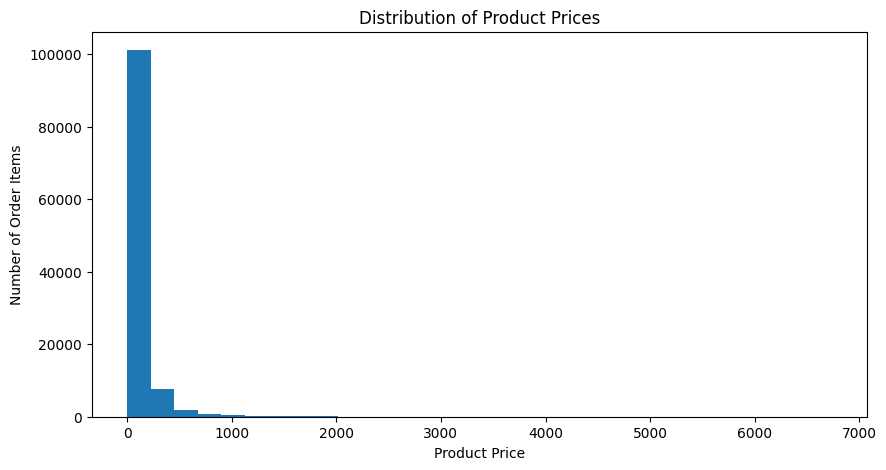

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(order_items['price'], bins=30)

plt.title("Distribution of Product Prices")
plt.xlabel("Product Price")
plt.ylabel("Number of Order Items")

plt.show()

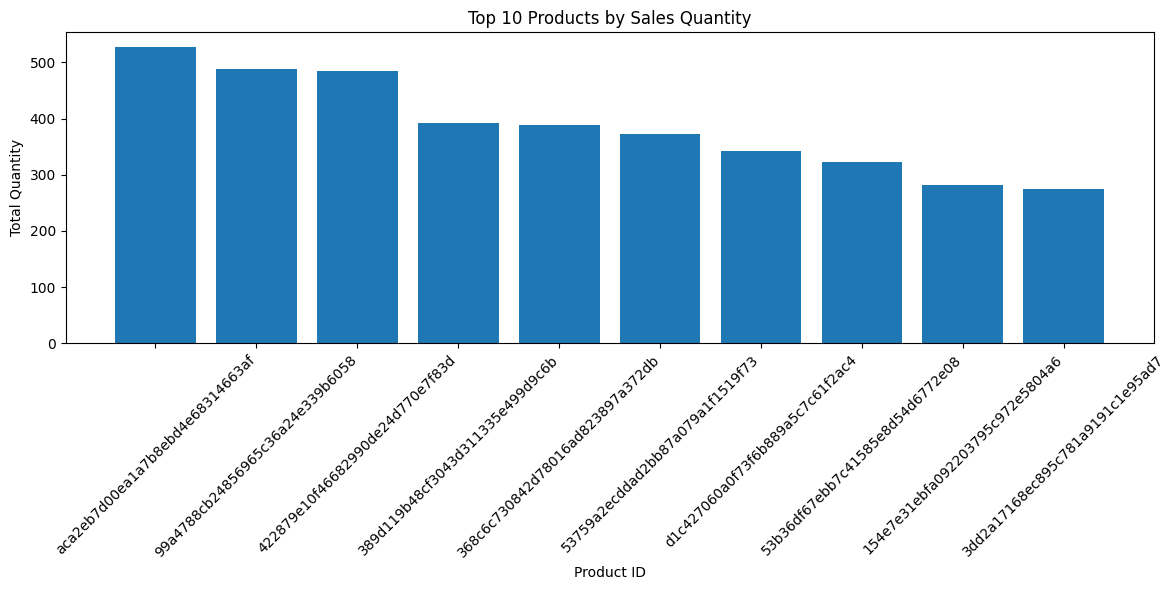

In [53]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_products['product_id'].astype(str),
    top_products['Total_Quantity']
)

plt.title("Top 10 Products by Sales Quantity")
plt.xlabel("Product ID")
plt.ylabel("Total Quantity")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:

# ==========================================
# STEP 1: COMBINE MAIN E-COMMERCE DATASETS
# ==========================================

# Merge Orders with Payments
combined_data = orders_clean.merge(
    payments,
    on='order_id',
    how='left'
)

# Merge with Order Items
combined_data = combined_data.merge(
    order_items,
    on='order_id',
    how='left'
)

print("COMBINED DATASET CREATED SUCCESSFULLY")

print("Total Rows:", combined_data.shape[0])
print("Total Columns:", combined_data.shape[1])

display(combined_data.head())


COMBINED DATASET CREATED SUCCESSFULLY
Total Rows: 118434
Total Columns: 20


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days,purchase_month,payment_sequential,payment_type,payment_installments,payment_value,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,2017-10,1.0,credit_card,1.0,18.12,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,2017-10,3.0,voucher,1.0,2.00,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,2017-10,2.0,voucher,1.0,18.59,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,2018-07,1.0,boleto,1.0,141.46,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,2018-08,1.0,credit_card,3.0,179.12,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22


In [55]:

# COMBINED DATASET INFORMATION

combined_info = pd.DataFrame({
    'Column Name': combined_data.columns,
    'Missing Values': combined_data.isnull().sum().values,
    'Data Type': combined_data.dtypes.astype(str).values
})

display(combined_info)


,Column Name,Missing Values,Data Type
0,order_id,0,object
1,customer_id,0,object
2,order_status,0,object
3,order_purchase_timestamp,0,datetime64[ns]
4,order_approved_at,176,datetime64[ns]
5,order_delivered_carrier_date,2074,datetime64[ns]
6,order_delivered_customer_date,3397,datetime64[ns]
7,order_estimated_delivery_date,0,datetime64[ns]
8,delivery_time_days,3397,float64
9,purchase_month,0,period[M]


In [56]:

combined_data.to_csv(
    'olist_combined_dataset.csv',
    index=False
)

print("Combined dataset saved successfully!")


Combined dataset saved successfully!


In [57]:
# Main E-commerce KPIs

total_orders = combined_orders['order_id'].nunique()
total_revenue = combined_orders['item_revenue'].sum()
average_order_value = combined_orders['item_revenue'].mean()
total_customers = combined_orders['customer_unique_id'].nunique()
total_items = combined_orders['item_count'].sum()

kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Orders',
        'Total Revenue',
        'Average Order Value',
        'Unique Customers',
        'Total Items Sold'
    ],
    'Value': [
        total_orders,
        round(total_revenue, 2),
        round(average_order_value, 2),
        total_customers,
        total_items
    ]
})

display(kpi_summary)

NameError: name 'combined_orders' is not defined

In [58]:
# Aggregate payment data by order
payments_by_order = payments.groupby('order_id', as_index=False).agg(
    payment_total=('payment_value', 'sum')
)

# Aggregate order items by order
items_by_order = order_items.groupby('order_id', as_index=False).agg(
    item_count=('order_id', 'size'),
    item_revenue=('price', 'sum'),
    freight_total=('freight_value', 'sum')
)

# Combine all datasets
combined_orders = orders_clean.merge(
    payments_by_order, on='order_id', how='left'
)

combined_orders = combined_orders.merge(
    items_by_order, on='order_id', how='left'
)

combined_orders = combined_orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

print("Combined dataset shape:", combined_orders.shape)

display(combined_orders.head())

Combined dataset shape: (99441, 15)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days,purchase_month,payment_total,item_count,item_revenue,freight_total,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,2017-10,38.71,1.0,29.99,8.72,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,2018-07,141.46,1.0,118.70,22.76,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,2018-08,179.12,1.0,159.90,19.22,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,2017-11,72.20,1.0,45.00,27.20,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,2018-02,28.62,1.0,19.90,8.72,72632f0f9dd73dfee390c9b22eb56dd6


In [59]:
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Orders',
        'Total Revenue',
        'Average Order Value',
        'Unique Customers',
        'Total Items Sold'
    ],
    'Value': [
        combined_orders['order_id'].nunique(),
        round(combined_orders['item_revenue'].sum(), 2),
        round(combined_orders['item_revenue'].mean(), 2),
        combined_orders['customer_unique_id'].nunique(),
        int(combined_orders['item_count'].sum())
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Orders,99441.00
1,Total Revenue,13591643.70
2,Average Order Value,137.75
3,Unique Customers,96096.00
4,Total Items Sold,112650.00


In [60]:
# Convert purchase date into monthly format
combined_orders['purchase_month'] = (
    combined_orders['order_purchase_timestamp']
    .dt.to_period('M').astype(str)
)

# Calculate monthly revenue and orders
monthly_revenue = combined_orders.groupby('purchase_month').agg(
    Total_Revenue=('item_revenue', 'sum'),
    Total_Orders=('order_id', 'nunique')
).reset_index()

# Display results
display(monthly_revenue)

,purchase_month,Total_Revenue,Total_Orders
0,2016-09,267.36,4
1,2016-10,49507.66,324
2,2016-12,10.90,1
3,2017-01,120312.87,800
4,2017-02,247303.02,1780
5,2017-03,374344.30,2682
6,2017-04,359927.23,2404
7,2017-05,506071.14,3700
8,2017-06,433038.60,3245
9,2017-07,498031.48,4026


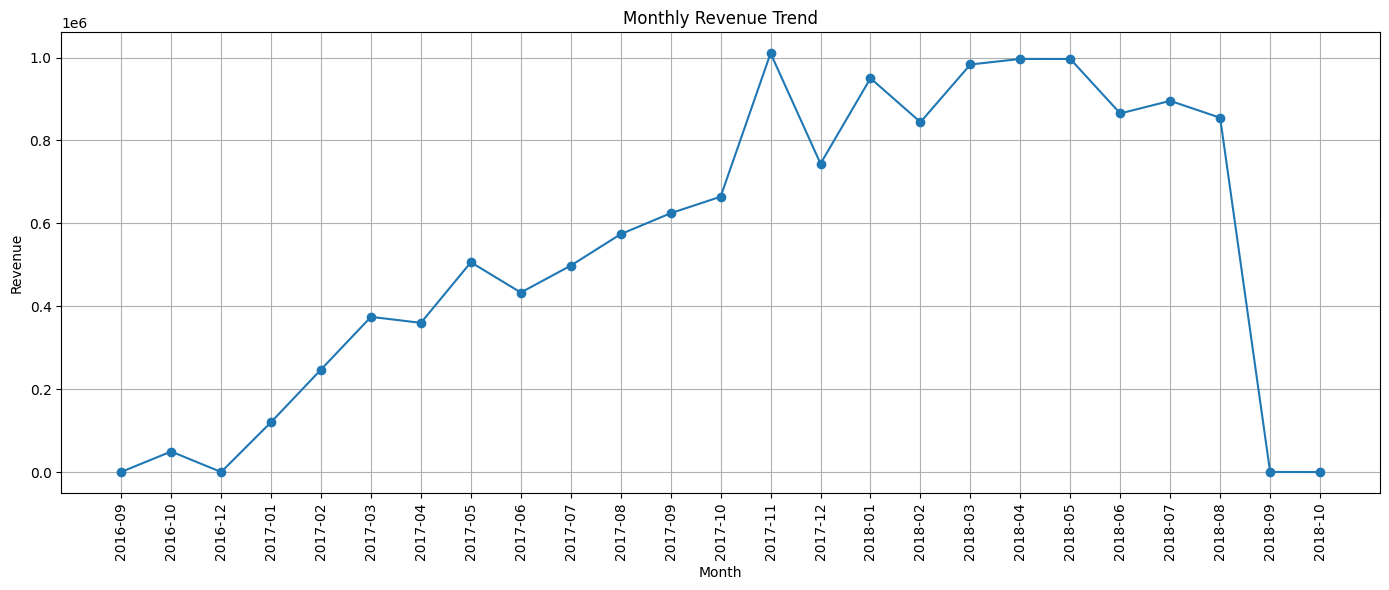

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue['purchase_month'],
    monthly_revenue['Total_Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [62]:
# Count orders placed by each unique customer
customer_orders = combined_orders.groupby('customer_unique_id').agg(
    total_orders=('order_id', 'nunique')
).reset_index()

# Categorise customers
customer_orders['customer_type'] = customer_orders['total_orders'].apply(
    lambda x: 'Repeat Customer' if x > 1 else 'One-Time Customer'
)

# Count customer types
customer_summary = customer_orders['customer_type'].value_counts().reset_index()

customer_summary.columns = ['Customer Type', 'Number of Customers']

# Calculate percentages
customer_summary['Percentage'] = (
    customer_summary['Number of Customers'] /
    customer_summary['Number of Customers'].sum()
) * 100

display(customer_summary.round(2))

,Customer Type,Number of Customers,Percentage
0,One-Time Customer,93099,96.88
1,Repeat Customer,2997,3.12


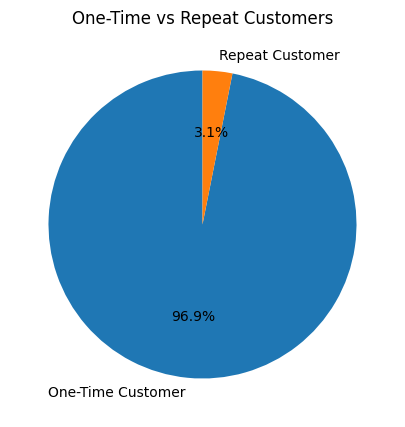

In [63]:
plt.figure(figsize=(7, 5))

plt.pie(
    customer_summary['Number of Customers'],
    labels=customer_summary['Customer Type'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('One-Time vs Repeat Customers')
plt.show()

In [64]:
# Calculate total spending per customer
customer_spending = combined_orders.groupby('customer_unique_id').agg(
    Total_Orders=('order_id', 'nunique'),
    Total_Spending=('item_revenue', 'sum')
).reset_index()

# Sort customers by spending
top_customers = customer_spending.sort_values(
    by='Total_Spending', ascending=False
).head(10)

display(top_customers.round(2))

,customer_unique_id,Total_Orders,Total_Spending
3826,0a0a92112bd4c708ca5fde585afaa872,1,13440.0
81962,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0
44447,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0
82808,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0
26205,459bef486812aa25204be022145caa62,1,6729.0
95806,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0
24121,4007669dec559734d6f53e029e360987,1,5934.6
89688,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0
35070,5d0a2980b292d049061542014e8960bf,1,4599.9
27441,48e1ac109decbb87765a3eade6854098,1,4590.0


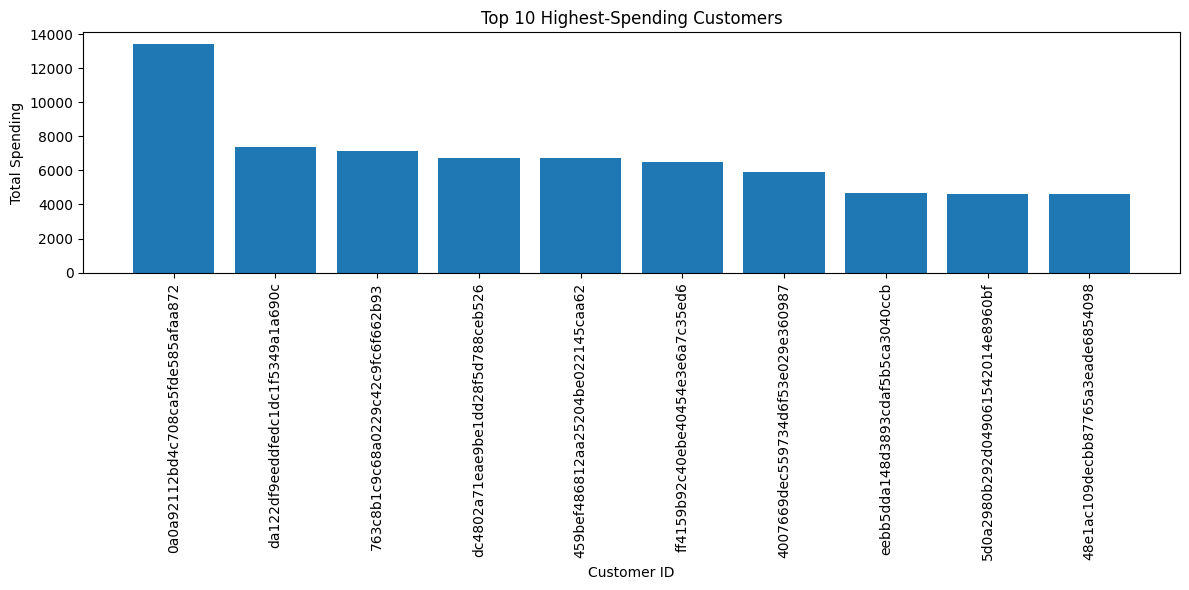

In [65]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_customers['customer_unique_id'].astype(str),
    top_customers['Total_Spending']
)

plt.title('Top 10 Highest-Spending Customers')
plt.xlabel('Customer ID')
plt.ylabel('Total Spending')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [67]:
import pandas as pd

# Set analysis date as one day after the last purchase date
analysis_date = combined_orders['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = combined_orders.groupby('customer_unique_id').agg(
    Recency=('order_purchase_timestamp',
             lambda x: (analysis_date - x.max()).days),
    Frequency=('order_id', 'nunique'),
    Monetary=('item_revenue', 'sum')
).reset_index()

display(rfm.head(10))

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,18.90
2,0000f46a3911fa3c0805444483337064,586,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,337,1,180.00
5,0004bd2a26a76fe21f786e4fbd80607f,195,1,154.00
6,00050ab1314c0e55a6ca13cf7181fecf,181,1,27.99
7,00053a61a98854899e70ed204dd4bafe,232,1,382.00
8,0005e1862207bf6ccc02e4228effd9a0,592,1,135.00
9,0005ef4cd20d2893f0d9fbd94d3c0d97,220,1,104.90


In [68]:
combined_orders.to_csv('Olist_Final_Analysis.csv', index=False)
print("Final dataset saved successfully!")

Final dataset saved successfully!


In [69]:
rfm_summary = pd.DataFrame({
    'Metric': ['Total Customers', 'Repeat Customers', 'One-Time Customers',
               'Average Recency (Days)', 'Average Customer Spending'],
    'Value': [
        len(rfm),
        (rfm['Frequency'] > 1).sum(),
        (rfm['Frequency'] == 1).sum(),
        round(rfm['Recency'].mean(), 2),
        round(rfm['Monetary'].mean(), 2)
    ]
})

display(rfm_summary)

,Metric,Value
0,Total Customers,96096.00
1,Repeat Customers,2997.00
2,One-Time Customers,93099.00
3,Average Recency (Days),288.74
4,Average Customer Spending,141.44


In [70]:
import sqlite3

# Create database
conn = sqlite3.connect('olist_database.db')

# Transfer dataframe into SQL table
combined_orders.to_sql(
    'orders',
    conn,
    if_exists='replace',
    index=False
)

print("Dataset successfully loaded into SQL!")

Dataset successfully loaded into SQL!


In [71]:
query = """
SELECT COUNT(DISTINCT order_id) AS Total_Orders
FROM orders;
"""

display(pd.read_sql_query(query, conn))

,Total_Orders
0,99441


In [72]:
query = """
SELECT ROUND(SUM(item_revenue), 2) AS Total_Revenue
FROM orders;
"""

display(pd.read_sql_query(query, conn))

,Total_Revenue
0,13591643.7


In [73]:
query = """
SELECT purchase_month,
       ROUND(SUM(item_revenue), 2) AS Monthly_Revenue
FROM orders
GROUP BY purchase_month
ORDER BY purchase_month;
"""

display(pd.read_sql_query(query, conn))

,purchase_month,Monthly_Revenue
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02
5,2017-03,374344.30
6,2017-04,359927.23
7,2017-05,506071.14
8,2017-06,433038.60
9,2017-07,498031.48


In [74]:
query = """
SELECT customer_unique_id,
       COUNT(DISTINCT order_id) AS Total_Orders,
       ROUND(SUM(item_revenue), 2) AS Total_Spending
FROM orders
GROUP BY customer_unique_id
ORDER BY Total_Spending DESC
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))

,customer_unique_id,Total_Orders,Total_Spending
0,0a0a92112bd4c708ca5fde585afaa872,1,13440.0
1,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0
2,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0
3,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0
4,459bef486812aa25204be022145caa62,1,6729.0
5,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0
6,4007669dec559734d6f53e029e360987,1,5934.6
7,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0
8,5d0a2980b292d049061542014e8960bf,1,4599.9
9,48e1ac109decbb87765a3eade6854098,1,4590.0


In [78]:
query = """
SELECT
    CASE
        WHEN (julianday(order_delivered_customer_date) - julianday(order_estimated_delivery_date)) > 0 THEN 'Delayed'
        ELSE 'On Time or Early'
    END AS delivery_performance,
    COUNT(*) AS Total_Orders
FROM orders
WHERE order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL
GROUP BY delivery_performance;
"""

display(pd.read_sql_query(query, conn))

,delivery_performance,Total_Orders
0,Delayed,7827
1,On Time or Early,88649


In [80]:
from google.colab import files

combined_orders.to_csv('Olist_Final_Analysis.csv', index=False)

files.download('Olist_Final_Analysis.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
conn.close()
files.download('olist_database.db')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>